In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

In [7]:
df = pd.read_csv('../data/processed/netflix_cleaned.csv')

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
df.shape

(8807, 12)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      8807 non-null   str  
 4   cast          8807 non-null   str  
 5   country       8807 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8807 non-null   str  
 9   duration      8807 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [9]:
df['date_added'] = pd.to_datetime(df['date_added'])

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8807 non-null   str           
 1   type          8807 non-null   str           
 2   title         8807 non-null   str           
 3   director      8807 non-null   str           
 4   cast          8807 non-null   str           
 5   country       8807 non-null   str           
 6   date_added    8797 non-null   datetime64[us]
 7   release_year  8807 non-null   int64         
 8   rating        8807 non-null   str           
 9   duration      8807 non-null   str           
 10  listed_in     8807 non-null   str           
 11  description   8807 non-null   str           
dtypes: datetime64[us](1), int64(1), str(10)
memory usage: 825.8 KB


In [13]:
df['type'].value_counts()


type
Movie      6131
TV Show    2676
Name: count, dtype: int64

In [14]:
df['type'].value_counts(normalize=True) * 100

type
Movie      69.615079
TV Show    30.384921
Name: proportion, dtype: float64

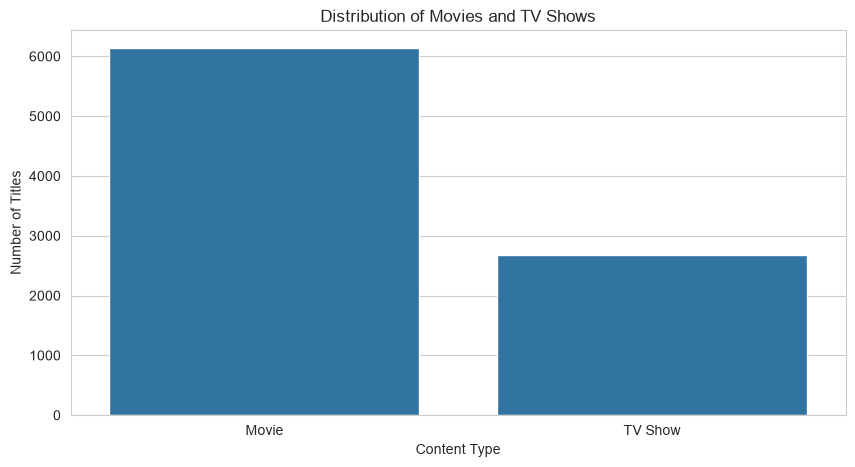

In [15]:
sns.countplot(data=df, x='type')

plt.title('Distribution of Movies and TV Shows')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')

plt.show()

In [16]:
df['country'].head(10)

0                                        United States
1                                         South Africa
2                                              Unknown
3                                              Unknown
4                                                India
5                                              Unknown
6                                              Unknown
7    United States, Ghana, Burkina Faso, United Kin...
8                                       United Kingdom
9                                        United States
Name: country, dtype: str

In [23]:
countries = df['country'].dropna().str.split(', ')
countries = countries.explode()
top_countries = countries.value_counts().head(10)

print(top_countries)


country
United States     3689
India             1046
Unknown            831
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Name: count, dtype: int64


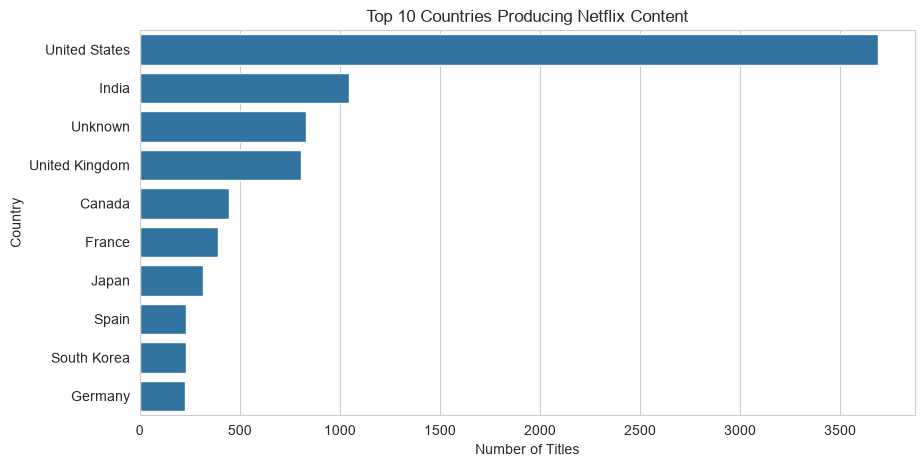

In [24]:
sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title('Top 10 Countries Producing Netflix Content')
plt.xlabel('Number of Titles')
plt.ylabel('Country')

plt.show()

In [25]:
df['release_year'].value_counts().sort_index()

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, Length: 74, dtype: int64

In [26]:
top_years = df['release_year'].value_counts().head(10)

print(top_years)

release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
2021     592
2015     560
2014     352
2013     288
2012     237
Name: count, dtype: int64


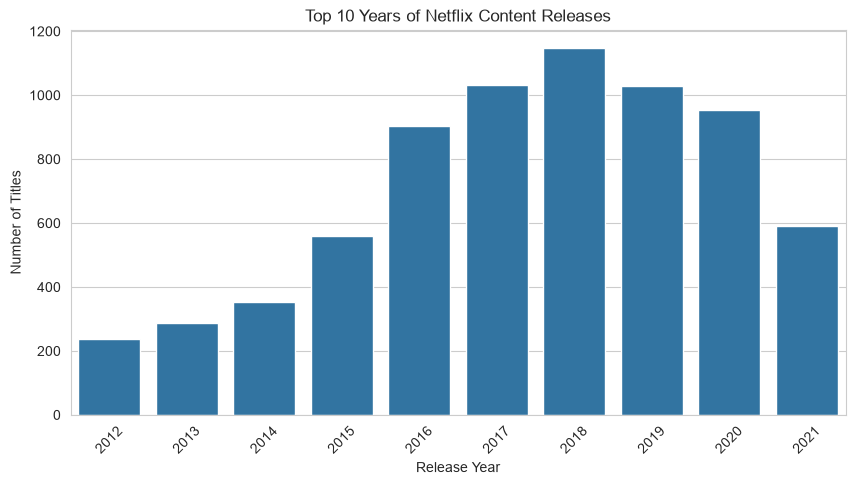

In [27]:
sns.barplot(
    x=top_years.index,
    y=top_years.values
)

plt.title('Top 10 Years of Netflix Content Releases')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.show()

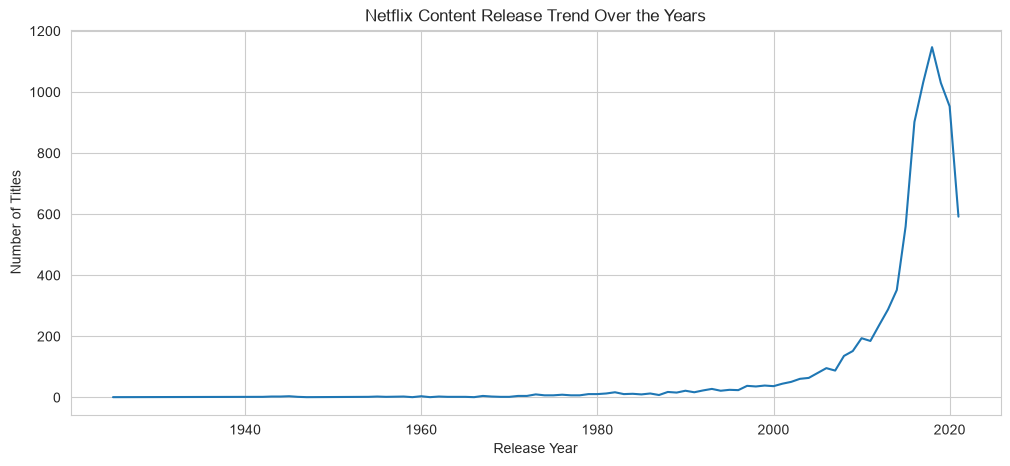

In [28]:
yearly_content = df['release_year'].value_counts().sort_index()

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=yearly_content.index,
    y=yearly_content.values
)

plt.title('Netflix Content Release Trend Over the Years')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.show()

In [29]:
df['type'].value_counts()

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

In [30]:
year_type = df.groupby(
    ['release_year', 'type']
).size().reset_index(name='count')

print(year_type.head())

   release_year     type  count
0          1925  TV Show      1
1          1942    Movie      2
2          1943    Movie      3
3          1944    Movie      3
4          1945    Movie      3


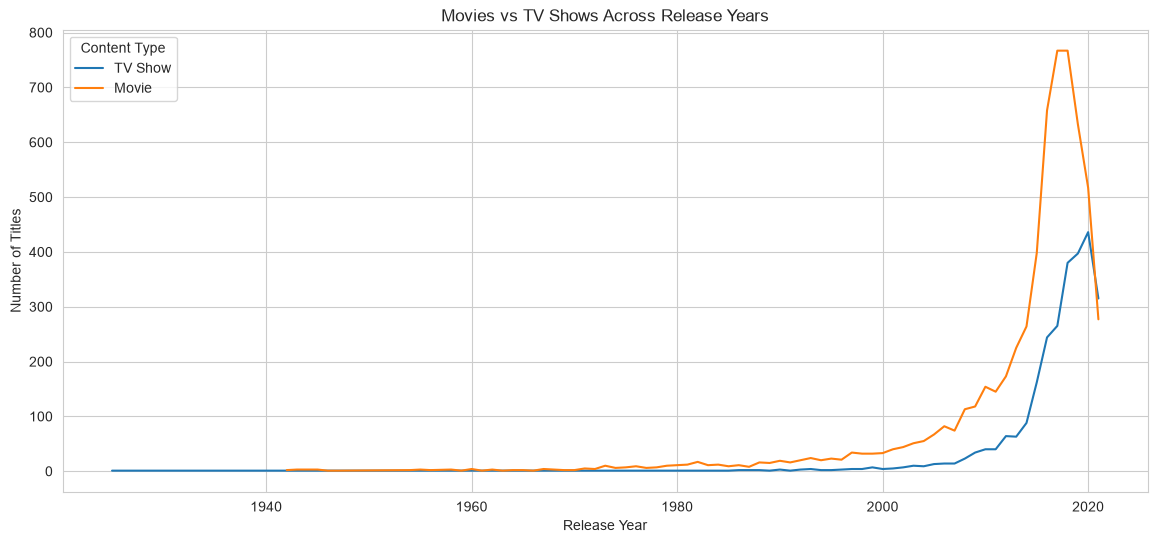

In [31]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=year_type,
    x='release_year',
    y='count',
    hue='type'
)

plt.title('Movies vs TV Shows Across Release Years')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.legend(title='Content Type')

plt.show()

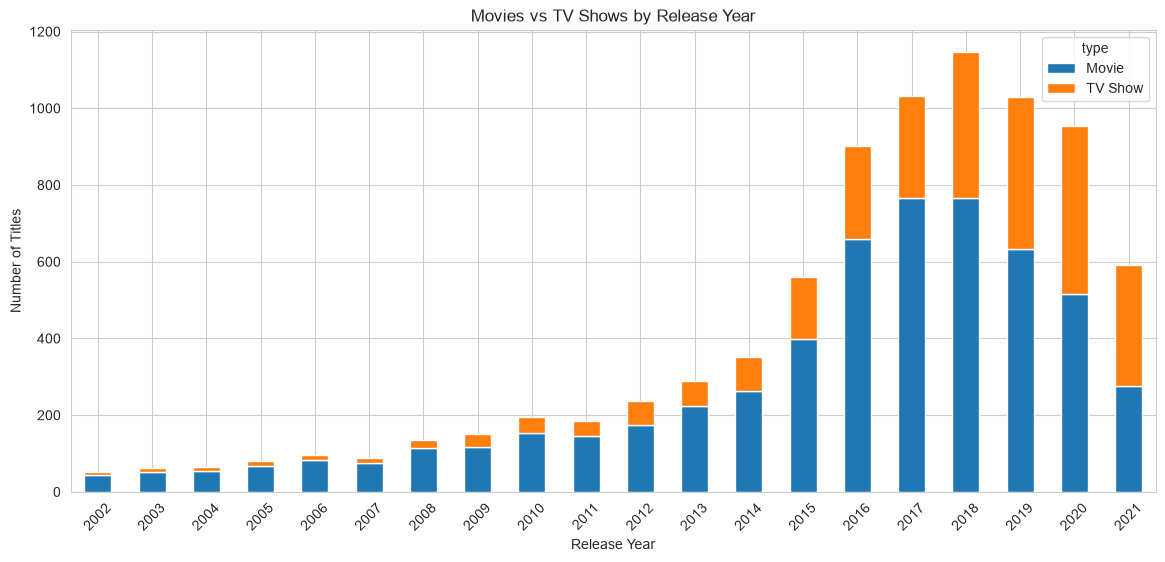

In [32]:
year_type_pivot = year_type.pivot(
    index='release_year',
    columns='type',
    values='count'
).fillna(0)

year_type_pivot.tail(20).plot(
    kind='bar',
    stacked=True,
    figsize=(14, 6)
)

plt.title('Movies vs TV Shows by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.show()

In [33]:
df['listed_in'].head(10)

0                                        Documentaries
1      International TV Shows, TV Dramas, TV Mysteries
2    Crime TV Shows, International TV Shows, TV Act...
3                               Docuseries, Reality TV
4    International TV Shows, Romantic TV Shows, TV ...
5                   TV Dramas, TV Horror, TV Mysteries
6                             Children & Family Movies
7     Dramas, Independent Movies, International Movies
8                         British TV Shows, Reality TV
9                                     Comedies, Dramas
Name: listed_in, dtype: str

In [35]:
genres = df['listed_in'].str.split(', ')
genres = genres.explode()
top_genres = genres.value_counts().head(10)

print(top_genres)

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


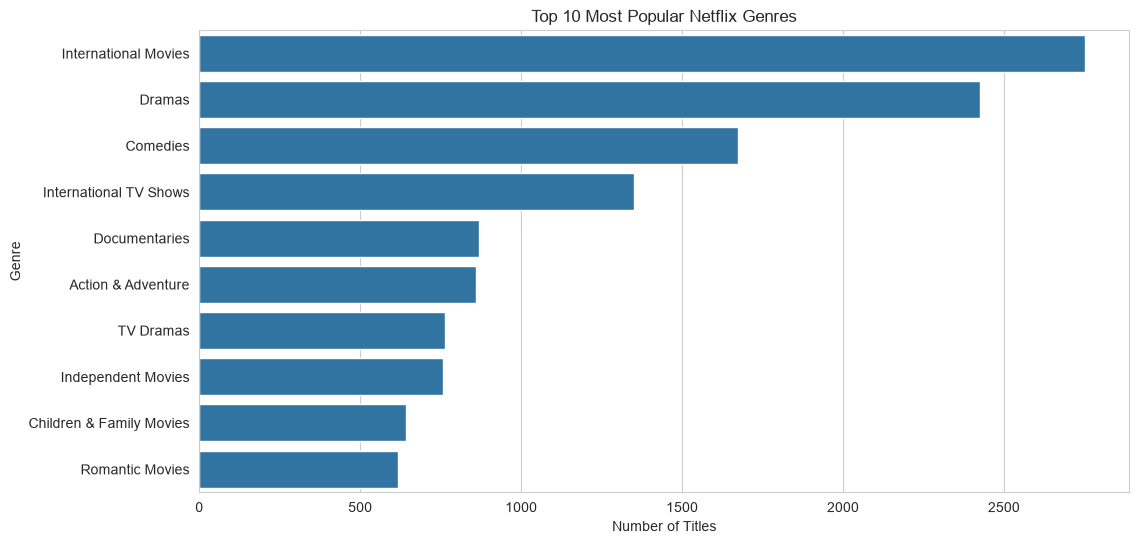

In [36]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title('Top 10 Most Popular Netflix Genres')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')

plt.show()

In [37]:
df['rating'].unique()

<StringArray>
[   'PG-13',    'TV-MA',       'PG',    'TV-14',    'TV-PG',     'TV-Y',
    'TV-Y7',        'R',     'TV-G',        'G',    'NC-17',  'Unknown',
       'NR', 'TV-Y7-FV',       'UR']
Length: 15, dtype: str

In [38]:
rating_counts = df['rating'].value_counts()

print(rating_counts)

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
Unknown        7
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


In [39]:
top_ratings = df['rating'].value_counts().head(10)

print(top_ratings)

rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: count, dtype: int64


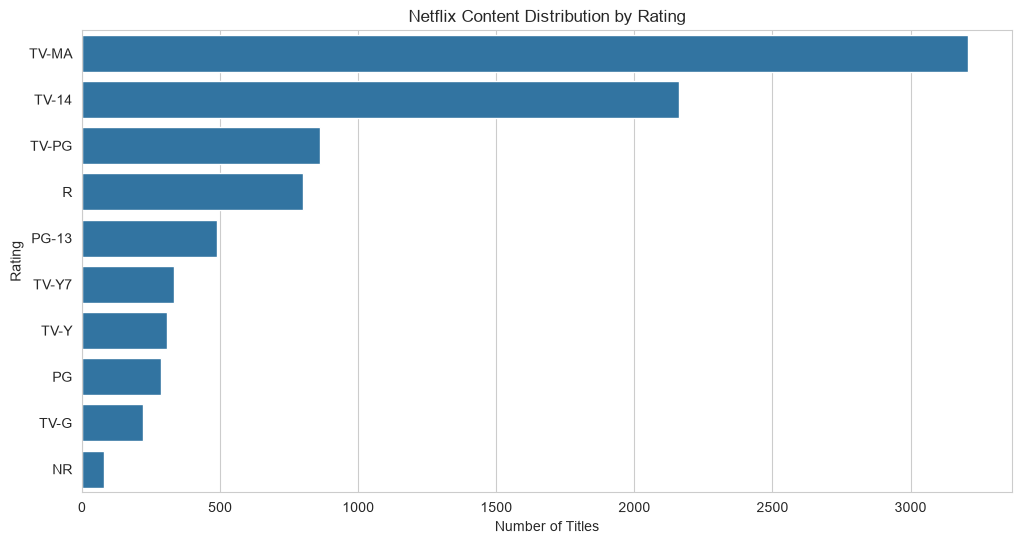

In [40]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_ratings.values,
    y=top_ratings.index
)

plt.title('Netflix Content Distribution by Rating')
plt.xlabel('Number of Titles')
plt.ylabel('Rating')

plt.show()

In [ ]:
movies = df[df['type'] == 'Movie']
tv_shows = df[df['type'] == 'TV Show']


In [42]:
movie_duration = movies['duration'].str.replace(' min', '', regex=False)

movie_duration = movie_duration.astype(int)

movie_duration.describe()

count    6131.000000
mean       99.564998
std        28.289504
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration, dtype: float64

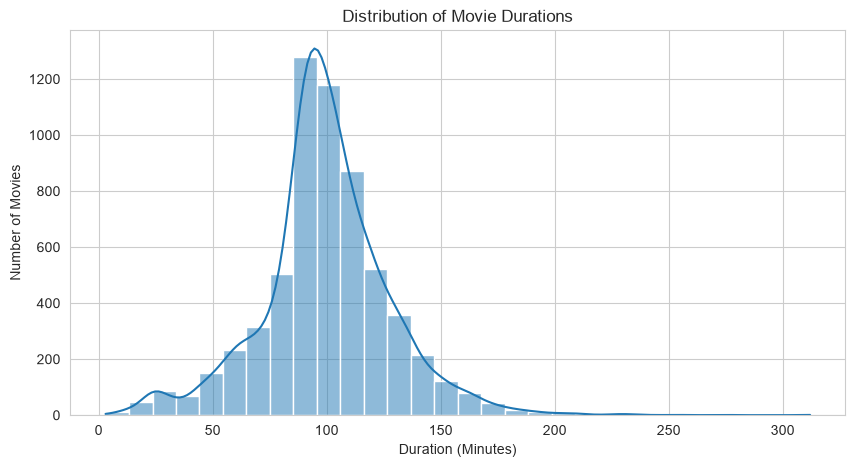

In [43]:
sns.histplot(movie_duration, bins=30, kde=True)

plt.title('Distribution of Movie Durations')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Number of Movies')
plt.show()

In [44]:
tv_seasons = tv_shows['duration'].str.replace(
    ' Season', '', regex=False
).str.replace('s', '', regex=False)

tv_seasons = tv_seasons.astype(int)

tv_seasons.value_counts().sort_index()

duration
1     1793
2      425
3      199
4       95
5       65
6       33
7       23
8       17
9        9
10       7
11       2
12       2
13       3
15       2
17       1
Name: count, dtype: int64